# Virtual try-on, part 2: a pretrained model (CatVTON)

Part 1 (`train_tryon_mac_v4.ipynb`) trained a warp + U-Net pipeline from scratch on the Mac at 256x192.
It reached SSIM 0.834 / LPIPS 0.164 / FID 25.9, but the pictures still had a blur band at the hem,
wavy stripes and washed-out prints.

Here we use a **pretrained** try-on model instead of training one:

- **CatVTON** (Chong et al., ICLR 2025, arXiv 2407.15886). Built on Stable Diffusion 1.5 inpainting.
- The person photo (with the top masked out) and the garment photo are **stacked into one image**.
  The UNet's self-attention then copies the garment into the masked area. No warping network, no text encoder.
- 899M parameters in total. Only the 49.6M self-attention weights were fine-tuned by the authors.
- Two checkpoints are used: `vitonhd-16k-512` (trained on VITON-HD at 512x384) for scoring, and `mix-48k-1024` (1024x768) for the full-size pictures.
- License: CC BY-NC-SA 4.0 (non-commercial, fine for a course project).

What we still do ourselves: build the try-on **mask** from our label maps and pose (old top, arms and neck,
minus face, hair, hands and trousers), run the model on the Mac (MPS), and score it with the **same code and the same test photos** as part 1.

In [1]:
import os, sys, json, time
os.environ['USE_TF'] = '0'
sys.path.insert(0, os.path.expanduser('~/virtual-tryon'))
from catvton_lib import *          # loader, mask builder, run()
import pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image as Show, display
OUT = os.path.expanduser('~/virtual-tryon/run_catvton')
print('device:', 'mps' if torch.backends.mps.is_available() else 'cpu', '| torch', torch.__version__)

device: mps | torch 2.8.0


## 1. The mask: where the new top is allowed to go

Same rule as CatVTON's own auto-masker, but built from the VITON-HD label maps we already cleaned in part 1:
the convex hull of the old top, arms and neck, with face, hair, hands (from the pose wrists) and trousers protected.
If the new garment is longer than the old top (measured from the garment photo and the shoulder width), the mask is opened further down,
so a hoodie is not cut off at the old shirt's hem. This avoids the shape leak we found in part 1.

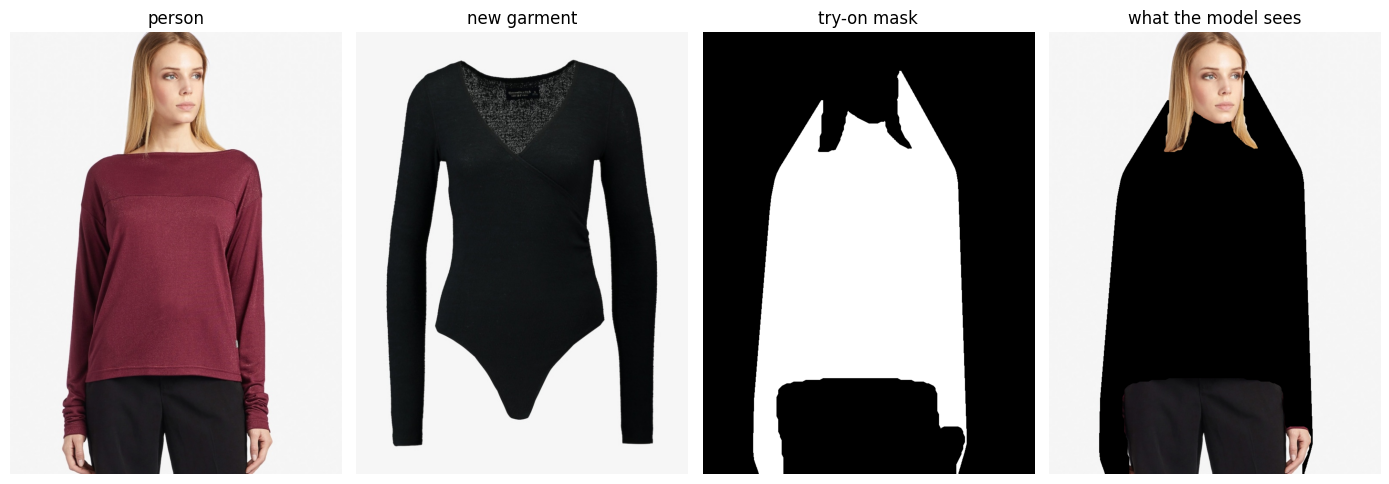

In [2]:
name, shirt = '05006_00.jpg', '11001_00.jpg'     # first official unpaired test pair
person = Image.open(f'{DATA}/test/image/{name}').convert('RGB')
m_short = tryon_mask(name, 'test', None, size=person.size, long_fit=False)
m_long = tryon_mask(name, 'test', shirt, size=person.size, long_fit=True)
fig, ax = plt.subplots(1, 4, figsize=(14, 5))
for a, im, t in zip(ax, [person, Image.open(f'{DATA}/test/cloth/{shirt}'), m_long,
                         Image.fromarray((np.array(person) * (1 - np.array(m_long)[..., None] / 255)).astype(np.uint8))],
                    ['person', 'new garment', 'try-on mask', 'what the model sees']):
    a.imshow(im, cmap='gray'); a.set_title(t); a.axis('off')
plt.tight_layout(); plt.show()

## 2. One live try-on on this Mac

512x384, 25 DDIM steps, guidance 2.5. Takes about 45 seconds on an M4 MacBook Air.
(1024x768 takes about 7 minutes per photo, so the full-size pictures below were made beforehand by `cat_showcase.py`.)

W1125 23:15:01.139000 87560 torch/distributed/elastic/multiprocessing/redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


  0%|          | 0/25 [00:00<?, ?it/s]

  4%|▍         | 1/25 [00:01<00:35,  1.48s/it]

  8%|▊         | 2/25 [00:02<00:33,  1.46s/it]

 12%|█▏        | 3/25 [00:04<00:31,  1.45s/it]

 16%|█▌        | 4/25 [00:05<00:29,  1.43s/it]

... (19 outputs left out)

 96%|█████████▌| 24/25 [00:33<00:01,  1.37s/it]

100%|██████████| 25/25 [00:34<00:00,  1.37s/it]

100%|██████████| 25/25 [00:34<00:00,  1.38s/it]

37 s


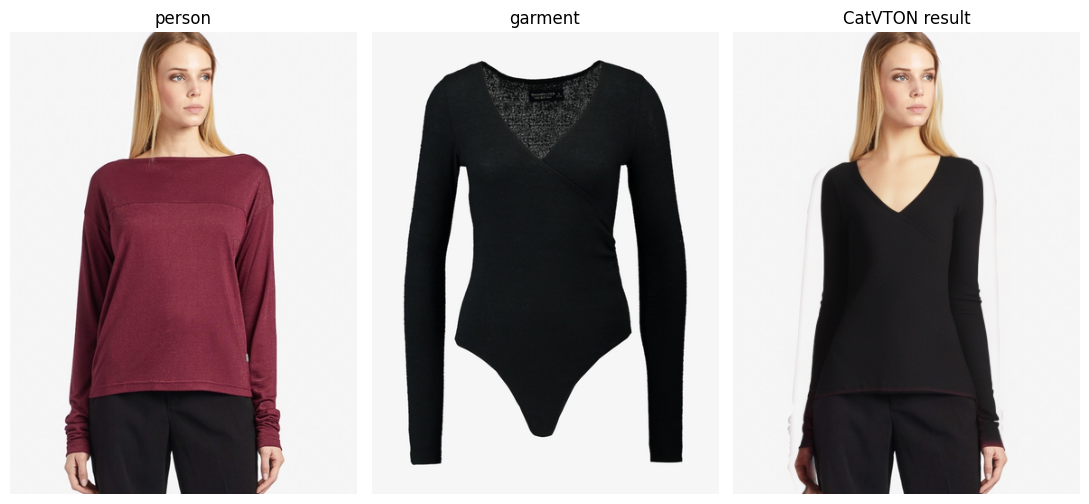

In [3]:
pipe = load_pipe('vitonhd')
t = time.time()
res, p, c, m = run(pipe, name, shirt, steps=25, size=(384, 512))
print(f'{time.time() - t:.0f} s')
fig, ax = plt.subplots(1, 3, figsize=(11, 5))
for a, im, tt in zip(ax, [p, c, res], ['person', 'garment', 'CatVTON result']):
    a.imshow(im); a.set_title(tt); a.axis('off')
plt.tight_layout(); plt.show()

## 3. Same person, same shirt: our v4 vs pretrained CatVTON (1024x768)

Each row uses a garment the person was **not** wearing (official unpaired test list), so there is no leakage.
Rows were chosen by rule, not by looks: 3 garments much longer than the old top, 3 with the busiest prints, 2 with the most bare arm.

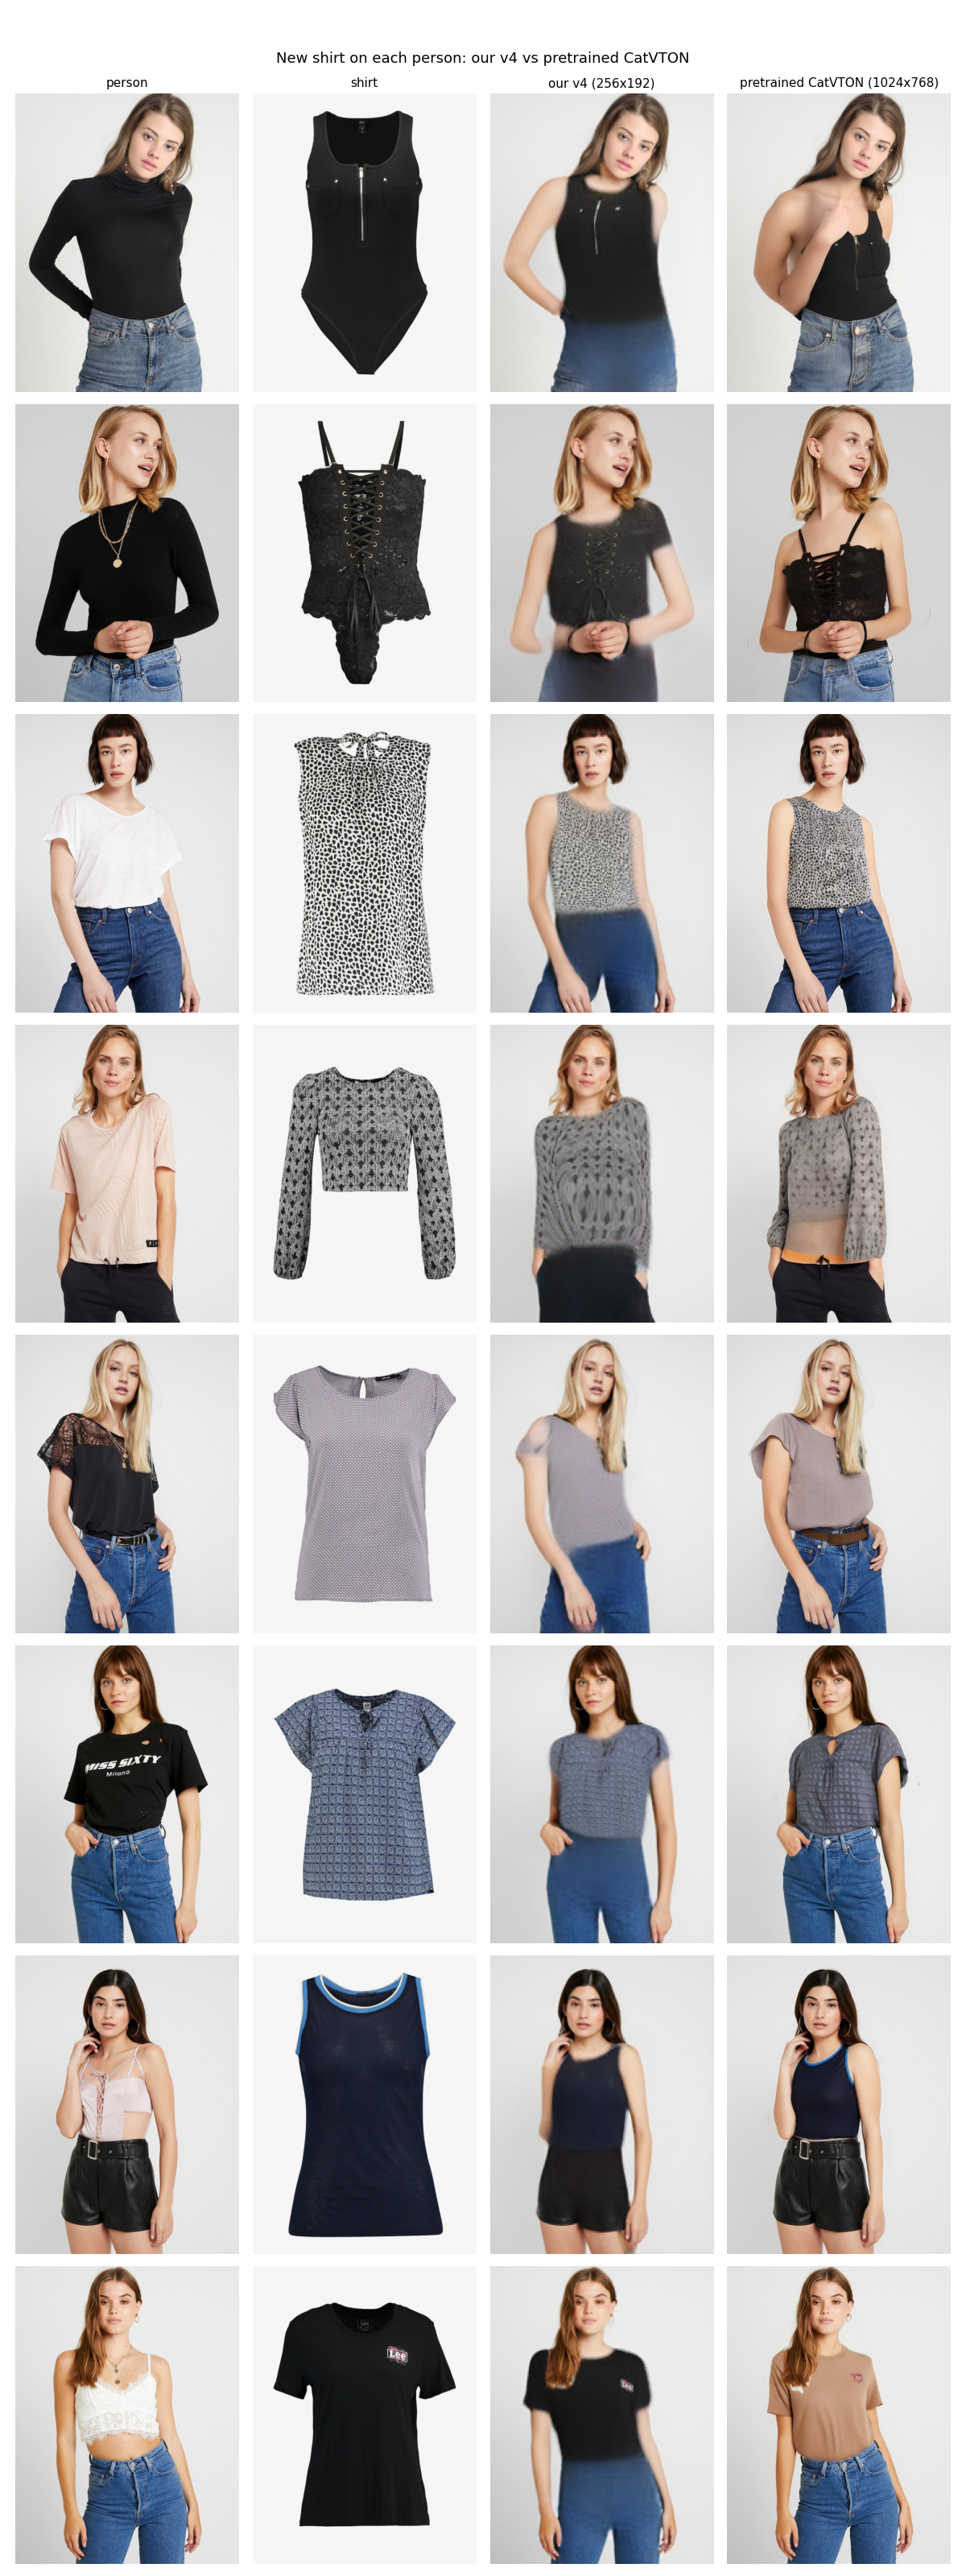

In [4]:
display(Show(f'{OUT}/catvton_new_shirts.png', width=900))

### Our v4's worst 4 photos, redone with CatVTON
These are the four lowest-SSIM test photos from part 1 (stripes and a grey tee).

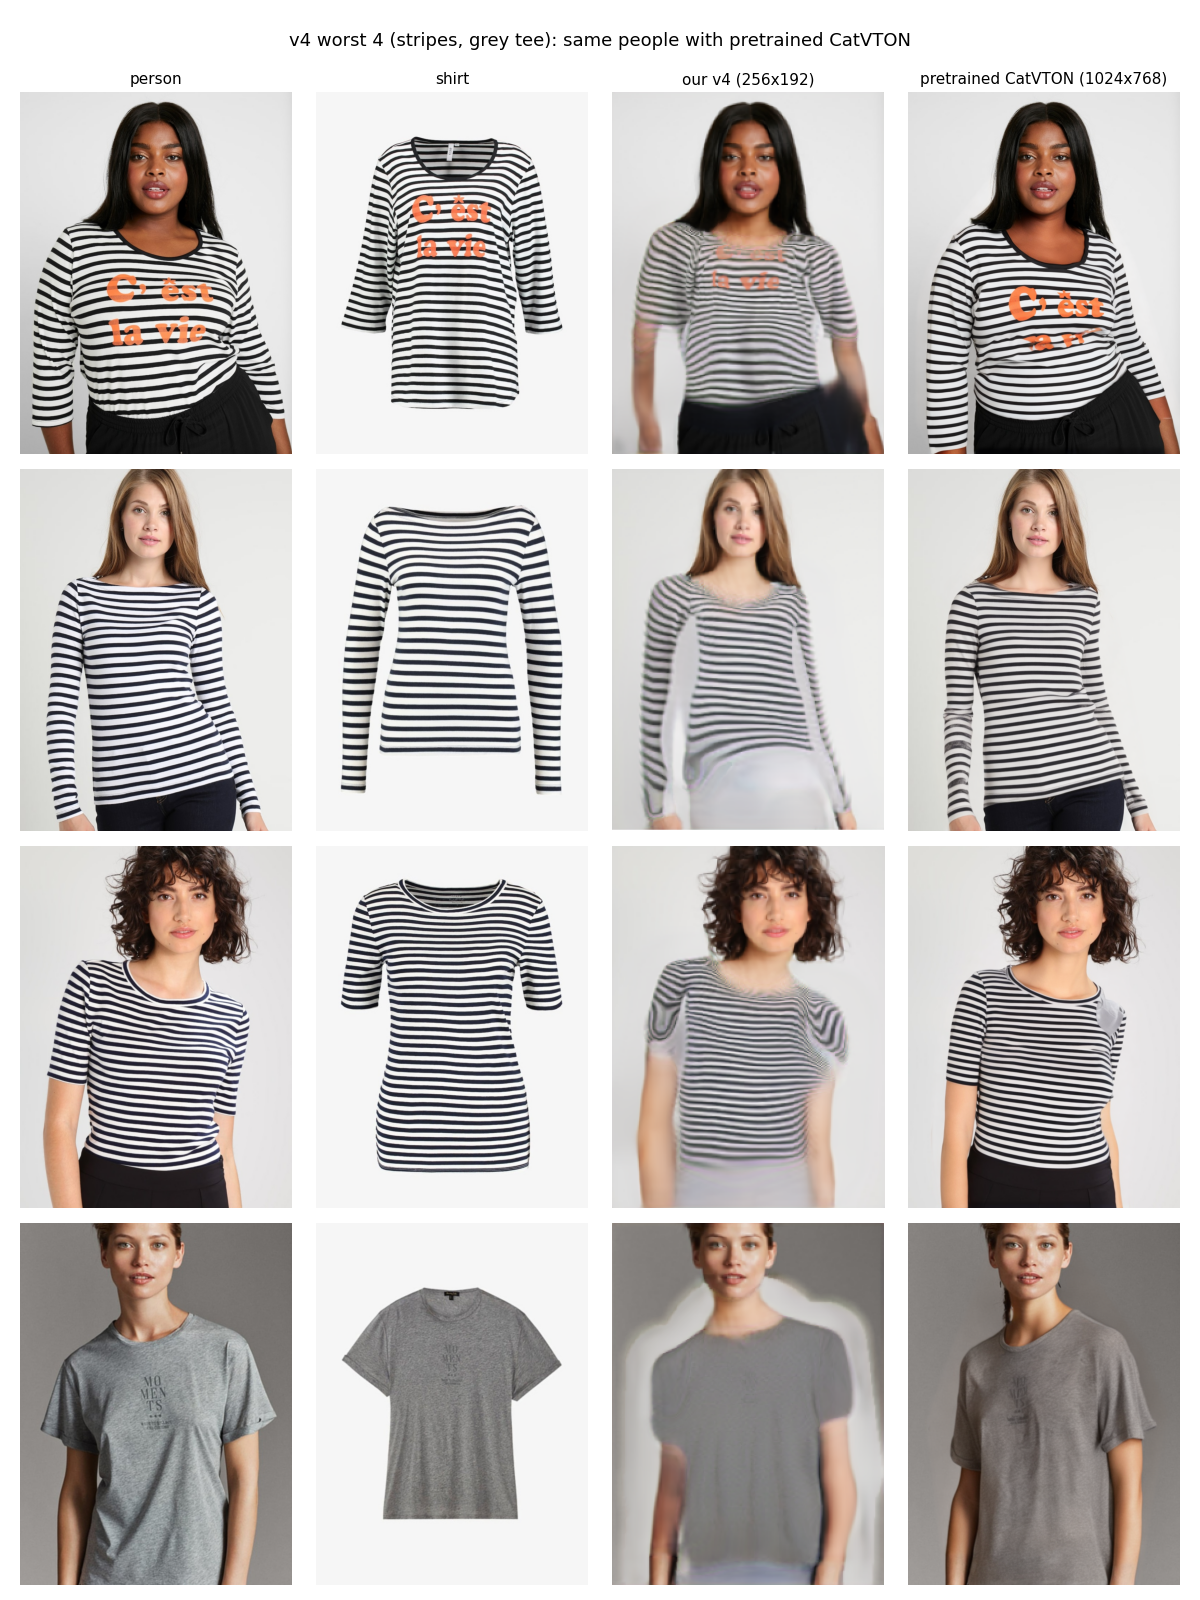

In [5]:
display(Show(f'{OUT}/catvton_vs_v4_worst.png', width=900))

## 4. Scores on the same test photos

Paired test (the person wears their own garment, so the real photo is the answer).
60 random test photos, the same 60 for both models. Same SSIM / LPIPS / PSNR code as part 1, all scored at 256x192.

In [6]:
s = json.load(open(f'{OUT}/scores.json'))
v4 = json.load(open(os.path.expanduser('~/virtual-tryon/run_v4/scores.json')))
table = pd.DataFrame({
    'our v4 (trained from scratch, 60 photos)': [s['our v4  SSIM'], s['our v4  LPIPS'], s['our v4  PSNR'], v4.get('unpaired FID')],
    'CatVTON pretrained (same 60 photos)': [s['CatVTON SSIM'], s['CatVTON LPIPS'], s['CatVTON PSNR'], None],
    'CatVTON paper (full test set)': [0.8704, 0.0565, None, 9.015],
    'VITON-HD paper (256x192)': [0.844, 0.062, None, 27.83],
}, index=['SSIM (higher better)', 'LPIPS (lower better)', 'PSNR dB (higher better)', 'unpaired FID (lower better)'])
print(s['CatVTON steps / size'])
table

vitonhd-16k-512 checkpoint, 25 DDIM steps, 512x384, scored at 256x192


,"our v4 (trained from scratch, 60 photos)",CatVTON pretrained (same 60 photos),CatVTON paper (full test set),VITON-HD paper (256x192)
SSIM (higher better),0.831,0.856,0.8704,0.844
LPIPS (lower better),0.163,0.104,0.0565,0.062
PSNR dB (higher better),21.000,21.370,NaN,NaN
unpaired FID (lower better),25.890,NaN,9.0150,27.830


CatVTON has lower LPIPS than v4 on 95% of the 60 photos


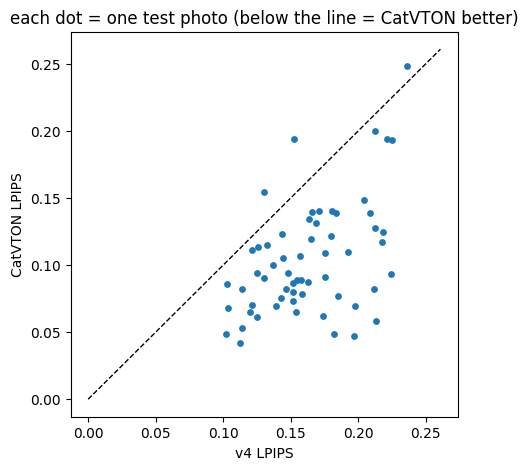

In [7]:
per4 = pd.read_csv(os.path.expanduser('~/virtual-tryon/run_v4/test_per_image.csv')).set_index('name')
cat = pd.read_csv(f'{OUT}/catvton_per_image.csv').set_index('name')
both = cat.join(per4, lsuffix='_cat', rsuffix='_v4')
wins = (both.lpips_cat < both.lpips_v4).mean()
print(f'CatVTON has lower LPIPS than v4 on {wins:.0%} of the {len(both)} photos')
plt.figure(figsize=(5, 5)); plt.scatter(both.lpips_v4, both.lpips_cat, s=15)
lim = [0, max(both.lpips_v4.max(), both.lpips_cat.max()) * 1.05]; plt.plot(lim, lim, 'k--', lw=1)
plt.xlabel('v4 LPIPS'); plt.ylabel('CatVTON LPIPS'); plt.title('each dot = one test photo (below the line = CatVTON better)')
plt.show()

## 5. Honest limits

- **Speed:** about 45 s per photo at 512x384 and about 7 min at 1024x768 on the M4 Air (no GPU). A real app needs a server GPU.
- **Short garments:** when the new top is much shorter than the old one, the model has to invent the belly or waistband below it, and it often leaves a blurry strip.
- **Odd arm poses:** an arm raised behind the hair can come out smeared.
- **Colour slips:** in one of the 8 new-shirt rows a black tee came out tan. Diffusion is random; another seed usually fixes it, but we show the first try.
- **Our scores are lower than the paper's** (LPIPS 0.104 vs 0.057). Our masks come from the label maps instead of the official agnostic masks, we use 25 steps instead of 50, fp16 on MPS, and only 60 photos.
- **Pale edges:** where the mask covers background next to a loose old top, the model repaints that background a little brighter, so a faint pale strip can show beside the arms (see the live example above).
- **License:** non-commercial only.

**Takeaway:** training from scratch on a laptop taught us the pipeline (cleaning, features, warping, the shape-leak bug),
but a pretrained diffusion model trained on the same dataset on large GPUs is far ahead in picture quality.